# Kibble Simulation controller
This notebook allows to run a specific experiment (the sequence of dynamic and static phases) and to display the results of the phases. It relies on the module `KibbleClasses` 
 
2026-10-26, DUGR


In [2]:
import pandas as pd
import matplotlib.pyplot as plt 
import json
import tkinter as tk
from tkinter import filedialog
import KibbleClasses

### Simulation
Chose an `experiment_xxx.json` file that contains the sequence of phases to be run; the different simulations are automatically launched. At the end you can visualize the results of the [dynamic phase](#dynamic-phase) or the [static phase](#static-phase)

In [ ]:
# mapping string names contained in the configuration to classes
phase_classes = {
    "DynamicPhaseC01": KibbleClasses.DynamicPhaseC01,
    "StaticPhaseC01": KibbleClasses.StaticPhaseC01
}

configurations_file = "C:/Users/gregor.dudle/OneDrive - OST/aFE/2026_Kibble/Python_Scripts/Configurations/configurations.json"
config_df = pd.DataFrame()    
config_df = pd.read_json(configurations_file)

window = tk.Tk()
window.wm_attributes('-topmost', 1)
window.withdraw()   # this supresses the tk window
experiment_filename = filedialog.askopenfilename(parent=window)


experiment_series = pd.Series()
experiment_series = pd.read_json(experiment_filename, typ='series')
step_counter = 1
for experiment in experiment_series:
    title = f"Step Nr. {step_counter}"
    print(title)
    print("="*len(title))
    
    try: 
        print(config_df[experiment]["class"])
        current = phase_classes[config_df[experiment]["class"]](config_df[experiment])
        current.load_simulate()
    except:
        print("Unknown class")
     
    step_counter += 1
    print("==========================================")
    print()

    
print("End of experiment")

Step Nr. 1
DynamicPhaseC01
Temporary directory already exists.
Simulation data and metadata will be stored in 'Simulation_20261026125750Z_res.json'
Motion
------
Period: 25
Amplitude: 0.004
Offset: 0

Simulation
----------
numberOfIntervals:1000
stopTime: 100
Trying to load C:/Users/gregor.dudle/OneDrive - OST/aFE/2026_Kibble/Modelica_Work/DynamicPhase/DynamicPhaseM03.mo ...  Success
Trying to load C:/Users/gregor.dudle/OneDrive - OST/aFE/2026_Kibble/Modelica_Work/Components/BIPM_Coil/BIPM_coil_2V4.mo ...  Success
Trying to load C:/Users/gregor.dudle/OneDrive - OST/aFE/2026_Kibble/Modelica_Work/Components/Motion_driver/triangular_position.mo ...  Success

Step Nr. 2
StaticPhaseC01
Temporary directory already exists.
Simulation data and metadata will be stored in 'Simulation_20261026125800Z_res.json'
Simulation
----------
numberOfIntervals:1000
stopTime: 100
main: StaticPhaseM03
Trying to load C:/Users/gregor.dudle/OneDrive - OST/aFE/2026_Kibble/Modelica_Work/StaticPhase/StaticPhaseM03.

### Static phase

{'id': '20261026132502Z',
 'date': '2026-10-26 14:25:13',
 'user': 'gregor.dudle',
 'KibbleBalanceModel': 'StaticPhaseM03',
 'WeightDriver': {'period': 30,
  'amplitude': 9.81,
  'rising': 0.2,
  'width': 14.8,
  'falling': 0.2},
 'PID': {'k': 0.1, 'Td': 1, 'Ti': 3},
 'Simulation': {'startTime': 0.0,
  'stopTime': 100.0,
  'numberOfIntervals': 1000,
  'tolerance': 1e-06,
  'method': 'dassl',
  'fileNamePrefix': 'StaticPhaseM03',
  'options': '',
  'outputFormat': 'csv',
  'variableFilter': '.*',
  'cflags': '',
  'simflags': '-override=Driver.period=30,Driver.amplitude=9.81,Driver.rising=0.2,Driver.width=14.8,Driver.falling=0.2,PID.k=0.1,PID.Td=1,PID.Ti=3'}}

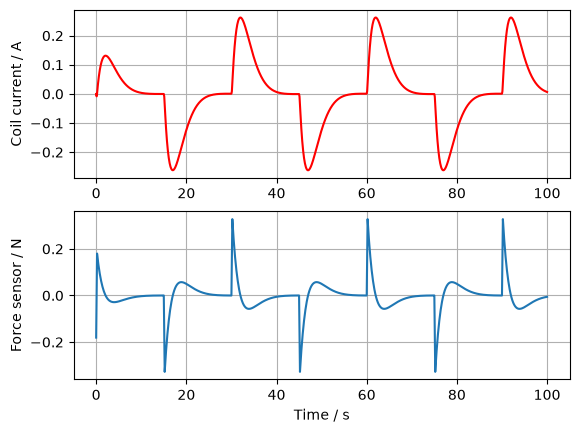

In [5]:
window = tk.Tk()
window.wm_attributes('-topmost', 1)
window.withdraw()   # this supress the tk window
res_filename = filedialog.askopenfilename(parent=window)

with open(res_filename) as f:
    data_meta = json.load(f)
    f.close()
if data_meta["metadata"]["KibbleBalanceModel"][0:11] != "StaticPhase":
    print("Error: This script is only for StaticPhase model results")
else:
    df = pd.DataFrame()

    display(data_meta["metadata"])
    data = pd.DataFrame(data_meta["data"])
    
    fig,ax = plt.subplots(2)
    #ax[0].plot(data["time"],data["B_l"])

    ax[0].plot(data["time"],data["PID.D.x"],"r")
    ax[0].grid()
    ax[0].set_ylabel("Coil current / A")
    ax[1].plot(data["time"],data["PID.D.y"])
    ax[1].grid()
    ax[1].set_ylabel("Force sensor / N")
    ax[1].set_xlabel("Time / s")

In [ ]:
print(data.columns.tolist())

['time', 'PID.D.x', 'PID.I.y', 'der(PID.D.x)', 'der(PID.I.y)', 'ForceSensor.f', 'GRD.p.i', 'GRD.p.v', 'Masse.f', 'PID.Add.y', 'PID.D.y', 'PID.P.y', 'PrgCurrentSource.v', 'R1.LossPower', 'R1.R_actual', 'R1.i', 'coil.magneticFieldTable.y', 'coil.p.v', 'coil.pos_a.f', 'fixed.flange.f', 'Driver.y', 'ForceSensor.flange_a.f', 'ForceSensor.flange_b.f', 'Masse.flange.f', 'PID.Add.u1', 'PID.Add.u2', 'PID.Add.u3', 'PID.D.u', 'PID.Gain.u', 'PID.Gain.y', 'PID.I.u', 'PID.P.u', 'PID.u', 'PID.y', 'PrgCurrentSource.i', 'PrgCurrentSource.n.i', 'PrgCurrentSource.n.v', 'PrgCurrentSource.p.i', 'PrgCurrentSource.p.v', 'R1.n.i', 'R1.n.v', 'R1.p.i', 'R1.p.v', 'R1.v', 'coil.n.i', 'coil.n.v', 'coil.p.i', 'coil.pos_b.f']


### Dynamic phase

{'id': '20261026132454Z',
 'date': '2026-10-26 14:25:02',
 'user': 'gregor.dudle',
 'KibbleBalanceModel': 'DynamicPhaseM03',
 'CoilModel': 'BIPM_coil_2V4',
 'MagneticField': 'BIPM_magnetic_field_01',
 'Motion': {'Driver': 'triangular_position',
  'Amplitude': 0.004,
  'Period': 25,
  'Offset': 0},
 'Simulation': {'startTime': 0.0,
  'stopTime': 100.0,
  'numberOfIntervals': 1000,
  'tolerance': 1e-06,
  'method': 'dassl',
  'fileNamePrefix': 'DynamicPhaseM03',
  'options': '',
  'outputFormat': 'csv',
  'variableFilter': '.*',
  'cflags': '',
  'simflags': "-override=peri=25,ampli=0.004,magTableFileName=\\'C:/Users/gregor.dudle/OneDrive - OST/aFE/2026_Kibble/Modelica_Work/Components/BIPM_MagneticField/BIPM_magnetic_field_01.csv\\'"}}

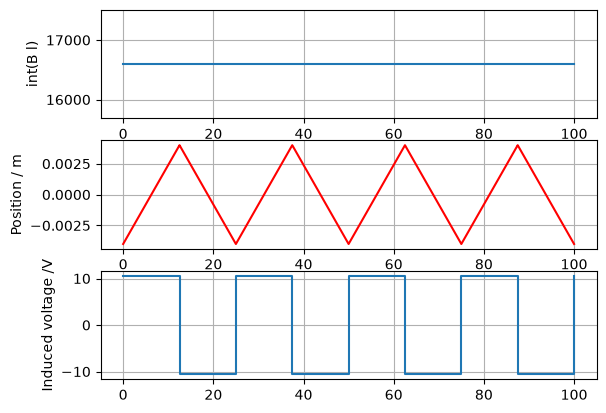

In [7]:
window = tk.Tk()
window.wm_attributes('-topmost', 1)
window.withdraw()   # this supress the tk window
filename = filedialog.askopenfilename(parent=window)

df = pd.DataFrame()

with open(filename) as f:
    data_meta = json.load(f)
    f.close()
if data_meta["metadata"]["KibbleBalanceModel"][0:12] != "DynamicPhase":
    print("Error: This script is only for DynamicPhase model results")
else:
    df = pd.DataFrame()


display(data_meta["metadata"])
data = pd.DataFrame(data_meta["data"])
data["B_l"] = data["coil.p.v"]/data["der(coil.pos_a.s)"]

fig,ax = plt.subplots(3)
ax[0].plot(data["time"],data["B_l"])
ax[0].set_ylabel("int(B l)")
ax[0].grid()
ax[1].plot(data["time"],data["coil.pos_a.s"],"r")
ax[1].set_ylabel("Position / m")
ax[1].grid()
ax[2].plot(data["time"],data["coil.p.v"])
ax[2].set_ylabel("Induced voltage /V")
ax[2].grid()